Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Extracting /content/archive.zip...
Found 400 images | Classes (1): ['fruit_0']
Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fruits_yolo_od/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, er

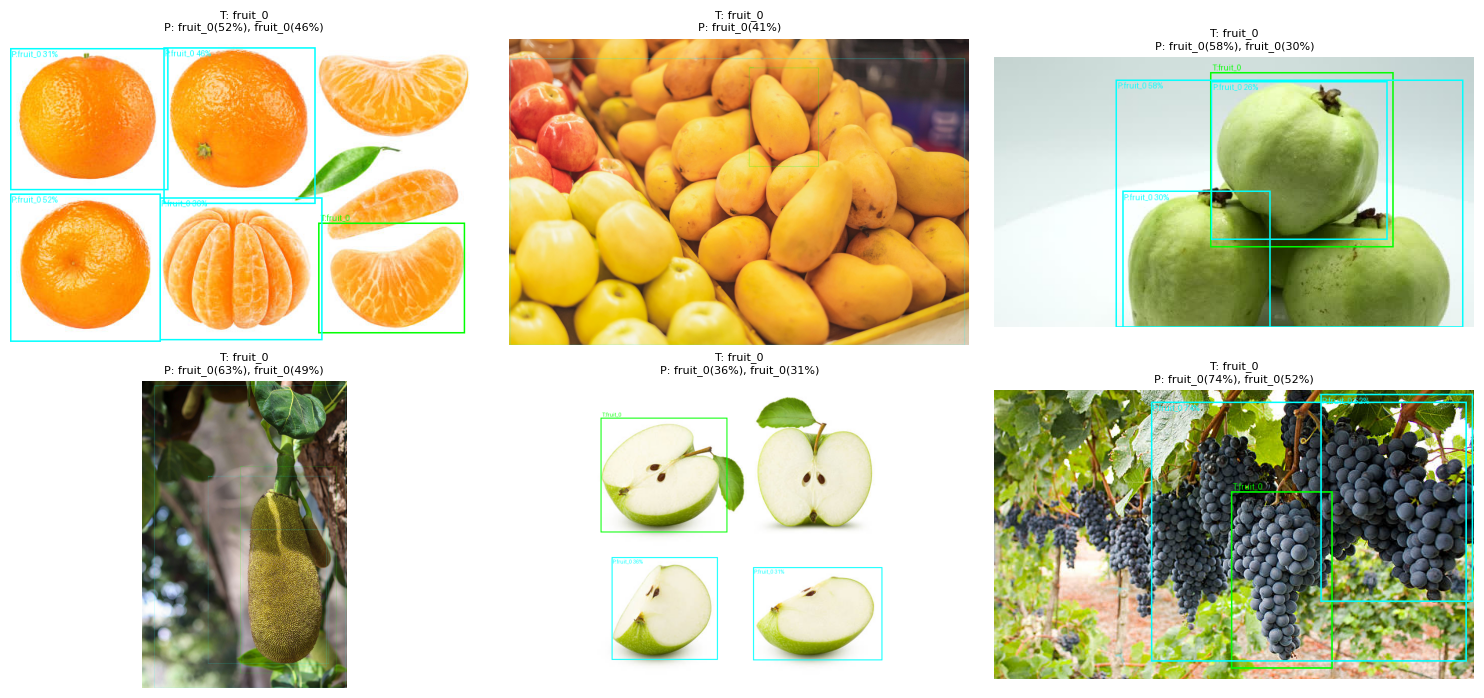

In [1]:
import os
import time
import glob
import yaml
import shutil
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

start_time = time.time()
random.seed(42)
np.random.seed(42)

try:
    from ultralytics import YOLO
except ImportError:
    !pip install -q ultralytics
    from ultralytics import YOLO

# ---------------------------------------------------------
# 1. EXTRACT ZIP & LOCATE IMAGES + YOLO LABELS
# ---------------------------------------------------------
zip_matches = glob.glob('/content/**/*.zip', recursive=True)
assert len(zip_matches) > 0, "Please upload the fruits dataset .zip file to Colab Files first!"

raw_dir = '/content/fruits_od_raw'
if not os.path.exists(raw_dir):
    print(f"Extracting {zip_matches[0]}...")
    with zipfile.ZipFile(zip_matches[0], 'r') as z:
        z.extractall(raw_dir)

img_exts = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
all_imgs = [
    p for p in glob.glob(f'{raw_dir}/**/*', recursive=True)
    if os.path.isfile(p) and os.path.splitext(p)[1].lower() in img_exts
]
assert len(all_imgs) > 0, "No image files found inside the extracted dataset."

# Map each image stem -> matching .txt label file (if present)
all_txts = [
    p for p in glob.glob(f'{raw_dir}/**/*.txt', recursive=True)
    if os.path.basename(p).lower() not in {'classes.txt', 'labels.txt', 'notes.txt', 'readme.txt'}
]
txt_by_stem = {}
for t in all_txts:
    stem = os.path.splitext(os.path.basename(t))[0]
    txt_by_stem[stem] = t

# Try reading class names from data.yaml or classes.txt if present
class_names = None
yaml_matches = glob.glob(f'{raw_dir}/**/*.yaml', recursive=True) + glob.glob(f'{raw_dir}/**/*.yml', recursive=True)
classes_txt_matches = glob.glob(f'{raw_dir}/**/classes.txt', recursive=True)

for yf in yaml_matches:
    try:
        with open(yf, 'r') as f:
            ydata = yaml.safe_load(f)
        if isinstance(ydata, dict) and 'names' in ydata:
            names_raw = ydata['names']
            if isinstance(names_raw, dict):
                class_names = [names_raw[k] for k in sorted(names_raw.keys(), key=lambda x: int(x))]
            elif isinstance(names_raw, list):
                class_names = names_raw
            break
    except Exception:
        pass

if not class_names and classes_txt_matches:
    with open(classes_txt_matches[0], 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    if lines:
        class_names = lines

# Inspect class IDs across label files if names aren't explicitly listed
max_cls_id = -1
for t in all_txts:
    with open(t, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                try:
                    cid = int(float(parts[0]))
                    if cid > max_cls_id:
                        max_cls_id = cid
                except ValueError:
                    pass

if not class_names:
    num_c = max(1, max_cls_id + 1)
    class_names = [f"fruit_{i}" for i in range(num_c)]

print(f"Found {len(all_imgs)} images | Classes ({len(class_names)}): {class_names}")

# ---------------------------------------------------------
# 2. BUILD CLEAN YOLO TRAIN / VAL DIRECTORY & data.yaml
# ---------------------------------------------------------
yolo_root = '/content/fruits_yolo_od'
if os.path.exists(yolo_root):
    shutil.rmtree(yolo_root)

for split in ['train', 'val']:
    os.makedirs(os.path.join(yolo_root, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(yolo_root, 'labels', split), exist_ok=True)

# Pair images with their label files (create empty label if none exists)
paired = []
for idx, img_path in enumerate(all_imgs):
    stem = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = txt_by_stem.get(stem, None)
    paired.append((idx, img_path, lbl_path))

random.shuffle(paired)
val_count = max(10, int(0.2 * len(paired)))
val_items = paired[:val_count]
train_items = paired[val_count:]

def copy_split(items, split_name):
    for uid, img_p, lbl_p in items:
        ext = os.path.splitext(img_p)[1].lower()
        unique_stem = f"img_{uid:04d}"
        dst_img = os.path.join(yolo_root, 'images', split_name, f"{unique_stem}{ext}")
        dst_lbl = os.path.join(yolo_root, 'labels', split_name, f"{unique_stem}.txt")
        shutil.copy2(img_p, dst_img)
        if lbl_p and os.path.exists(lbl_p):
            shutil.copy2(lbl_p, dst_lbl)
        else:
            open(dst_lbl, 'w').close()

copy_split(train_items, 'train')
copy_split(val_items, 'val')

data_yaml_path = os.path.join(yolo_root, 'data.yaml')
with open(data_yaml_path, 'w') as f:
    yaml.safe_dump({
        'path': yolo_root,
        'train': 'images/train',
        'val': 'images/val',
        'nc': len(class_names),
        'names': class_names
    }, f, sort_keys=False)

# ---------------------------------------------------------
# 3. TRAIN YOLO OBJECT DETECTOR ON CPU (< 2 MINUTES)
# ---------------------------------------------------------
model = YOLO('yolo11n.pt')  # Lightweight detection model fast on CPU

model.train(
    data=data_yaml_path,
    epochs=8,
    imgsz=224,
    batch=16,
    device='cpu',
    workers=2,
    project='/content/runs',
    name='fruits_od_cpu',
    exist_ok=True,
    verbose=True
)

metrics = model.val(data=data_yaml_path, imgsz=224, batch=16, device='cpu', verbose=False)
map50 = float(metrics.box.map50) * 100.0
map50_95 = float(metrics.box.map) * 100.0
elapsed = time.time() - start_time

print(f"\nValidation mAP@50: {map50:.2f}% | mAP@50-95: {map50_95:.2f}%")
print(f"Total Execution Time: {elapsed:.1f} seconds")

# ---------------------------------------------------------
# 4. VISUALIZE PREDICTIONS (P) vs GROUND TRUTH (T)
# ---------------------------------------------------------
val_img_paths = sorted(glob.glob(os.path.join(yolo_root, 'images', 'val', '*')))
sample_paths = val_img_paths[:6]
preds = model.predict(source=sample_paths, imgsz=224, conf=0.25, device='cpu', verbose=False)

plt.figure(figsize=(15, 7))
for i, img_p in enumerate(sample_paths):
    img = Image.open(img_p).convert('RGB')
    w, h = img.size
    draw = ImageDraw.Draw(img)

    # Draw True (T) bounding boxes in green
    stem = os.path.splitext(os.path.basename(img_p))[0]
    gt_lbl = os.path.join(yolo_root, 'labels', 'val', f"{stem}.txt")
    true_names = []
    if os.path.exists(gt_lbl):
        with open(gt_lbl, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cid = int(float(parts[0]))
                    cx, cy, bw, bh = map(float, parts[1:5])
                    x1 = (cx - bw / 2.0) * w
                    y1 = (cy - bh / 2.0) * h
                    x2 = (cx + bw / 2.0) * w
                    y2 = (cy + bh / 2.0) * h
                    cname = class_names[cid] if 0 <= cid < len(class_names) else str(cid)
                    true_names.append(cname)
                    draw.rectangle([x1, y1, x2, y2], outline='lime', width=2)
                    draw.text((x1 + 2, max(0, y1 - 12)), f"T:{cname}", fill='lime')

    # Draw Predicted (P) bounding boxes in red/cyan
    pred_names = []
    boxes = preds[i].boxes
    if boxes is not None and len(boxes) > 0:
        for b in boxes:
            x1, y1, x2, y2 = b.xyxy[0].tolist()
            cid = int(b.cls[0].item())
            conf = float(b.conf[0].item()) * 100.0
            pname = preds[i].names[cid]
            pred_names.append(f"{pname}({conf:.0f}%)")
            draw.rectangle([x1, y1, x2, y2], outline='cyan', width=2)
            draw.text((x1 + 2, y1 + 2), f"P:{pname} {conf:.0f}%", fill='cyan')

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(
        f"T: {', '.join(set(true_names)) or 'None'}\nP: {', '.join(pred_names[:2]) or 'None'}",
        fontsize=8
    )
    plt.axis('off')

plt.tight_layout()
plt.show()